# DTNet maze pipeline

Trains DTNet (recurrent ResNet with recall and progressive loss, Bansal et al. 2022)
on mazes from the training generators, then tests whether it generalizes to
**unseen generators**, **larger mazes** and **mazes with loops** (10% of walls removed),
by running more recurrent iterations at test time.

A test maze counts as solved only if every passage pixel is labelled correctly.
With walls removed there can be several routes, and the target is the shortest one,
so a model that finds a longer valid route is scored as wrong.

## Setup

In [2]:
import contextlib
import os
import subprocess
import sys
import time
from pathlib import Path

REPO_URL = "https://github.com/yoshi0428/maze-generalization.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    # Colab: clone the repo (or update an existing clone) under /content.
    root = Path("/content/maze-generalization")
    if root.is_dir():
        subprocess.run(["git", "-C", str(root), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
else:
    # Local: the notebook runs from the repo root or notebooks/.
    root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset, TensorDataset
from tqdm.auto import tqdm

from dataset import make_test_datasets, make_train_dataset, stratified_split
from models.dt_net import DTNetRecall, evaluate, predict, solved_by_iters, train_step

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True
print("device:", device, torch.cuda.get_device_name() if device.type == "cuda" else "")

device: cuda NVIDIA GeForce RTX 5060 Ti


## Config

`QUICK = True` shrinks everything for a fast end-to-end check (results are meaningless).

Tests follow the proposal: sizes 63 up to 511 (8x larger). Training uses size 15: in the
2026-11-08 experiments (`results/`), DTNet trained at 15 solved 100% of size-63, 96% of
size-127 and 69% of size-511 test mazes. Training at 63 from scratch with 50 iterations
did not learn at all; fine-tuning at 63 needs ~150 iterations (batch 4 on 16 GB) and was
no better. Training with loops (`TRAIN_WALL_REMOVAL > 0`) badly hurt extrapolation.

DTNet passes information only a few pixels per iteration (5 convolutions per step), so the
number of iterations needed grows with the path length: training uses `MAX_ITERS` and
testing goes up to thousands of iterations. Size-511 mazes take about 20 ms per maze per
iteration even in bf16, which is why they get few test mazes.

In [3]:
QUICK = os.environ.get("MAZE_QUICK") == "1"
SEED = 0

# Data
TRAIN_GENERATORS = ["dfs", "prim", "kruskal"]   # or a single name, e.g. "dfs"
TRAIN_SIZE = 15                                 # maze width inside the border (odd); 63 -> 65 x 65 image
N_TRAIN = 30_000
TRAIN_WALL_REMOVAL = 0.0                        # or a per-maze range like (0.0, 0.1); hurt extrapolation
VAL_FRACTION = 0.1

TEST_GENERATORS = ["eller", "wilson", "hunt_and_kill", "recursive_division", "sidewinder"]
# Test size -> (number of mazes, eval batch size). Large mazes are slow to solve with
# thousands of iterations, so they get fewer mazes.
TEST_SIZES = {63: (200, 50), 127: (100, 25), 255: (40, 8), 511: (16, 2)}
WALL_REMOVALS = [0.0, 0.1]

# Model and training
WIDTH = 128
MAX_ITERS = 30          # training iterations; must be enough to solve training mazes (~150 at size 63)
ALPHA = 0.01           # weight of the progressive loss
EPOCHS = 20
BATCH_SIZE = 64          # at size 63: 16 fits 50 iterations, 4 fits 150 (16 GB GPU)
LR = 1e-3
WARMUP_EPOCHS = 2
AMP = device.type == "cuda"   # bf16 autocast: ~2-3x faster, ~1/3 the memory, same accuracy

# Evaluation
TEST_ITERS = [30, 100, 300, 1000, 3000]

if QUICK:
    N_TRAIN, EPOCHS, WIDTH, MAX_ITERS, WARMUP_EPOCHS = 600, 2, 32, 10, 0
    TEST_SIZES, TEST_ITERS = {15: (20, 10), 31: (20, 10)}, [10, 30]

RUN_NAME = "dtnet"                               # checkpoint name; change it per experiment
CHECKPOINT = root / "checkpoints" / f"{RUN_NAME}{'_quick' if QUICK else ''}.pt"
autocast = (lambda: torch.autocast("cuda", dtype=torch.bfloat16)) if AMP else contextlib.nullcontext
torch.manual_seed(SEED)
np.random.seed(SEED)

## Data

Training mazes are split evenly across `TRAIN_GENERATORS`; the validation split keeps the
same mix. With `TRAIN_WALL_REMOVAL > 0`, each training maze has a fraction of walls removed
(a range draws one per maze), so the model also sees mazes with loops. Samples are generated
once and kept in memory as uint8, so epochs don't regenerate them.

In [4]:
def materialize(ds, desc, batch_size=64):
    """Generate every sample once and stack them into an in-memory uint8 TensorDataset."""
    loader = DataLoader(ds, batch_size=batch_size, num_workers=min(8, os.cpu_count() or 1))
    # Start the workers before tqdm draws its bar: forking after it breaks Jupyter's messaging.
    batches = iter(loader)
    xs, ys = zip(*((x.to(torch.uint8), y.to(torch.uint8))
                   for x, y in tqdm(batches, total=len(loader), desc=desc, leave=False)))
    return TensorDataset(torch.cat(xs), torch.cat(ys))


def to_device(x, y):
    return x.to(device, non_blocking=True).float(), y.to(device, non_blocking=True).float()


t0 = time.time()
train_full = make_train_dataset(TRAIN_GENERATORS, size=TRAIN_SIZE, num_samples=N_TRAIN, seed=SEED,
                                wall_removal=TRAIN_WALL_REMOVAL)
train_split, val_split = stratified_split(train_full, VAL_FRACTION, seed=SEED)

all_train = materialize(train_full, "train mazes")
train_data = Subset(all_train, train_split.indices)
val_data = Subset(all_train, val_split.indices)

test_data = {}  # (wall_removal, size) -> TensorDataset
for wr in WALL_REMOVALS:
    for size, (n, _) in TEST_SIZES.items():
        ds = make_test_datasets(TEST_GENERATORS, size, n, train_generators=train_full.generator_names,
                                seed=SEED + 1, wall_removal=wr)[size]
        test_data[wr, size] = materialize(ds, f"test size={size} wr={wr}", batch_size=max(1, n // 8))

print(f"generated in {time.time() - t0:.0f}s")
print("train:", len(train_data), " val:", len(val_data), " generators:", train_full.generator_names)
for (wr, size), ds in test_data.items():
    print(f"test  size={size:3d} wall_removal={wr}: {len(ds)} mazes, input {tuple(ds[0][0].shape)}")

generated in 14s
train: 27000  val: 3000  generators: ['dfs', 'prim', 'kruskal']
test  size= 63 wall_removal=0.0: 200 mazes, input (3, 65, 65)
test  size=127 wall_removal=0.0: 100 mazes, input (3, 129, 129)
test  size=255 wall_removal=0.0: 40 mazes, input (3, 257, 257)
test  size=511 wall_removal=0.0: 16 mazes, input (3, 513, 513)
test  size= 63 wall_removal=0.1: 200 mazes, input (3, 65, 65)
test  size=127 wall_removal=0.1: 100 mazes, input (3, 129, 129)
test  size=255 wall_removal=0.1: 40 mazes, input (3, 257, 257)
test  size=511 wall_removal=0.1: 16 mazes, input (3, 513, 513)


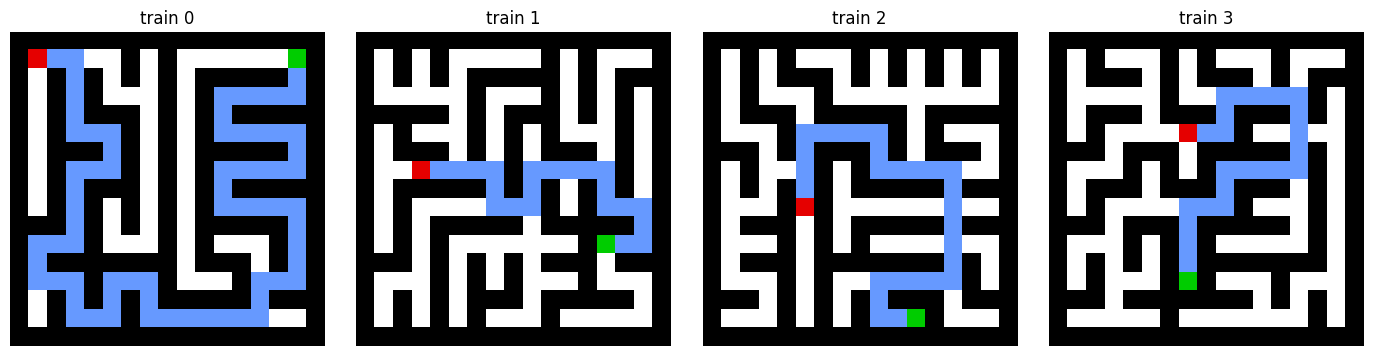

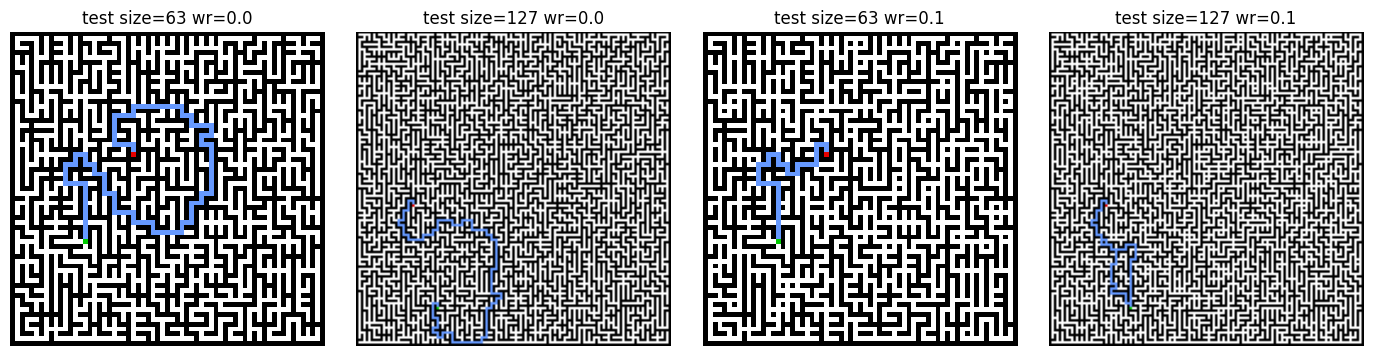

In [5]:
def render(x, y=None, pred=None):
    """RGB image: black wall, white passage, blue path, green start, red exit.

    With `pred`, blue = correct path pixels, orange = missed, magenta = wrongly predicted.
    """
    img = x[0, :, :, None].repeat(1, 1, 3).float()
    if y is not None and pred is None:
        img[y[0] == 1] = torch.tensor([0.4, 0.6, 1.0])
    if pred is not None:
        img[(y[0] == 1) & (pred[0] == 1)] = torch.tensor([0.4, 0.6, 1.0])
        img[(y[0] == 1) & (pred[0] == 0)] = torch.tensor([1.0, 0.6, 0.0])
        img[(y[0] == 0) & (pred[0] == 1)] = torch.tensor([0.9, 0.2, 0.9])
    img[x[1] == 1] = torch.tensor([0.0, 0.8, 0.0])
    img[x[2] == 1] = torch.tensor([0.9, 0.0, 0.0])
    return img


def show(images, titles=(), ncols=4):
    ncols = min(ncols, len(images))
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3.5 * nrows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images):
            ax.imshow(images[i])
            ax.set_title(titles[i] if i < len(titles) else "")
    plt.tight_layout()
    plt.show()


show([render(*train_data[i]) for i in range(4)], titles=[f"train {i}" for i in range(4)])
show([render(*test_data[wr, s][0]) for wr in WALL_REMOVALS for s in list(TEST_SIZES)[:2]],
     titles=[f"test size={s} wr={wr}" for wr in WALL_REMOVALS for s in list(TEST_SIZES)[:2]])

## Model

In [6]:
model = DTNetRecall(in_channels=3, width=WIDTH).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, pin_memory=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, pin_memory=True)

# Linear warmup, then cosine decay to zero, stepped once per batch.
total_steps = EPOCHS * len(train_loader)
warmup_steps = WARMUP_EPOCHS * len(train_loader)

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + np.cos(np.pi * progress))

sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
print(f"params: {sum(p.numel() for p in model.parameters()):,}")

params: 783,504


## Train

Each epoch reports the training loss, the validation loss at `MAX_ITERS` and the fraction of
validation mazes solved at `MAX_ITERS`. The best checkpoint has the most validation mazes
solved, with ties broken by the lower validation loss. The training loss includes the
progressive-loss term (weight `ALPHA`), so it sits slightly above the validation loss.

In [7]:
def solved_rate(model, loader, iters, desc="eval"):
    """Fraction of mazes solved after each iteration count."""
    solved = {t: [] for t in iters}
    with autocast():
        for x, y in tqdm(loader, desc=desc, leave=False):
            for t, ok in solved_by_iters(model, *to_device(x, y), iters).items():
                solved[t].append(ok.cpu())
    return {t: torch.cat(v).float().mean().item() for t, v in solved.items()}


def validate(model, loader):
    """(mean loss, fraction solved) at MAX_ITERS."""
    total, solved = 0.0, []
    with autocast():
        for x, y in tqdm(loader, desc="validation", leave=False):
            loss, ok = evaluate(model, *to_device(x, y), MAX_ITERS)
            total += loss * len(x)
            solved.append(ok.cpu())
    return total / len(loader.dataset), torch.cat(solved).float().mean().item()


history = {"train_loss": [], "val_loss": [], "val_solved": []}
best = (-1.0, float("inf"))  # (val solved, val loss)
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

for epoch in tqdm(range(EPOCHS), desc="epochs"):
    t0, losses = time.time(), []
    batches = tqdm(train_loader, desc=f"epoch {epoch + 1}", leave=False)
    for x, y in batches:
        with autocast():
            losses.append(train_step(model, opt, *to_device(x, y), max_iters=MAX_ITERS, alpha=ALPHA))
        sched.step()
        batches.set_postfix(loss=f"{losses[-1]:.4f}")

    val_loss, val_solved = validate(model, val_loader)
    history["train_loss"].append(float(np.mean(losses)))
    history["val_loss"].append(val_loss)
    history["val_solved"].append(val_solved)

    if (val_solved, -val_loss) > (best[0], -best[1]):
        best = (val_solved, val_loss)
        torch.save(model.state_dict(), CHECKPOINT)

    tqdm.write(f"epoch {epoch + 1:3d}/{EPOCHS}  train loss {history['train_loss'][-1]:.4f}  "
               f"val loss {val_loss:.4f}  val solved {val_solved:.1%}  "
               f"lr {sched.get_last_lr()[0]:.2e}  {time.time() - t0:.0f}s")

model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
print(f"best: val solved {best[0]:.1%}, val loss {best[1]:.4f}  (checkpoint: {CHECKPOINT})")

epochs:   5%|▌         | 1/20 [00:56<18:00, 56.89s/it]

epoch   1/20  train loss 0.6557  val loss 0.4110  val solved 0.5%  lr 5.01e-04  57s


epochs:  10%|█         | 2/20 [01:48<16:06, 53.71s/it]

epoch   2/20  train loss 0.4286  val loss 0.1725  val solved 48.3%  lr 1.00e-03  51s


epochs:  15%|█▌        | 3/20 [02:40<15:01, 53.06s/it]

epoch   3/20  train loss 0.1605  val loss 0.0047  val solved 99.1%  lr 9.92e-04  52s


... (30 outputs left out)

epochs:  95%|█████████▌| 19/20 [18:28<01:09, 69.36s/it]

epoch  19/20  train loss 0.0008  val loss 0.0001  val solved 100.0%  lr 7.60e-06  54s


epochs: 100%|██████████| 20/20 [19:23<00:00, 58.19s/it]

epoch  20/20  train loss 0.0005  val loss 0.0002  val solved 100.0%  lr 0.00e+00  55s
best: val solved 100.0%, val loss 0.0001  (checkpoint: /home/yoshi0428/PycharmProjects/maze-generalization/checkpoints/dtnet.pt)


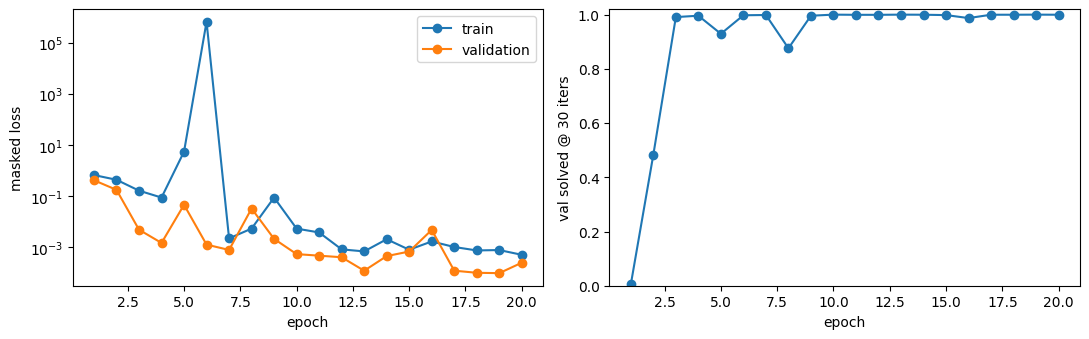

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
epochs = range(1, len(history["train_loss"]) + 1)
ax1.plot(epochs, history["train_loss"], marker="o", label="train")
ax1.plot(epochs, history["val_loss"], marker="o", label="validation")
ax1.set(xlabel="epoch", ylabel="masked loss", yscale="log")
ax1.legend()
ax2.plot(epochs, history["val_solved"], marker="o")
ax2.set(xlabel="epoch", ylabel=f"val solved @ {MAX_ITERS} iters", ylim=(0, 1.02))
plt.tight_layout()
plt.show()

## Test on unseen generators

Fraction of test mazes solved after each number of iterations, for every size and
wall-removal setting. Larger mazes have longer paths, so they need more iterations.

In [9]:
results = {}
t0 = time.time()
for (wr, size), ds in tqdm(test_data.items(), desc="test settings"):
    results[wr, size] = solved_rate(model, DataLoader(ds, batch_size=TEST_SIZES[size][1]), TEST_ITERS,
                                    desc=f"size={size} wr={wr}")

print(f"evaluated in {time.time() - t0:.0f}s\n")

header = f"{'wall_removal':>12} {'size':>5} " + " ".join(f"{t:>7}" for t in TEST_ITERS)
print(header + "   (iterations)")

for (wr, size), r in results.items():
    print(f"{wr:>12} {size:>5} " + " ".join(f"{r[t]:>7.1%}" for t in TEST_ITERS))

test settings:   0%|          | 0/8 [03:34<?, ?it/s]


KeyboardInterrupt: 

In [10]:
fig, axes = plt.subplots(1, len(WALL_REMOVALS), figsize=(5.5 * len(WALL_REMOVALS), 3.8), squeeze=False)

for ax, wr in zip(axes[0], WALL_REMOVALS):
    for size in TEST_SIZES:
        ax.plot(TEST_ITERS, [results[wr, size][t] for t in TEST_ITERS], marker="o", label=f"size {size}")
    ax.axvline(MAX_ITERS, color="gray", ls="--", lw=1)
    ax.set(xscale="log", xlabel="test iterations", ylabel="solved", ylim=(0, 1),
           title=f"wall removal {wr:.0%}")
    ax.legend()

plt.tight_layout()
plt.show()

KeyError: (0.0, 63)

## Predictions

One test maze per setting after the largest iteration count.
Blue = correct path, orange = missed path pixels, magenta = wrongly predicted pixels.

predictions: 100%|██████████| 8/8 [03:18<00:00, 24.77s/it]


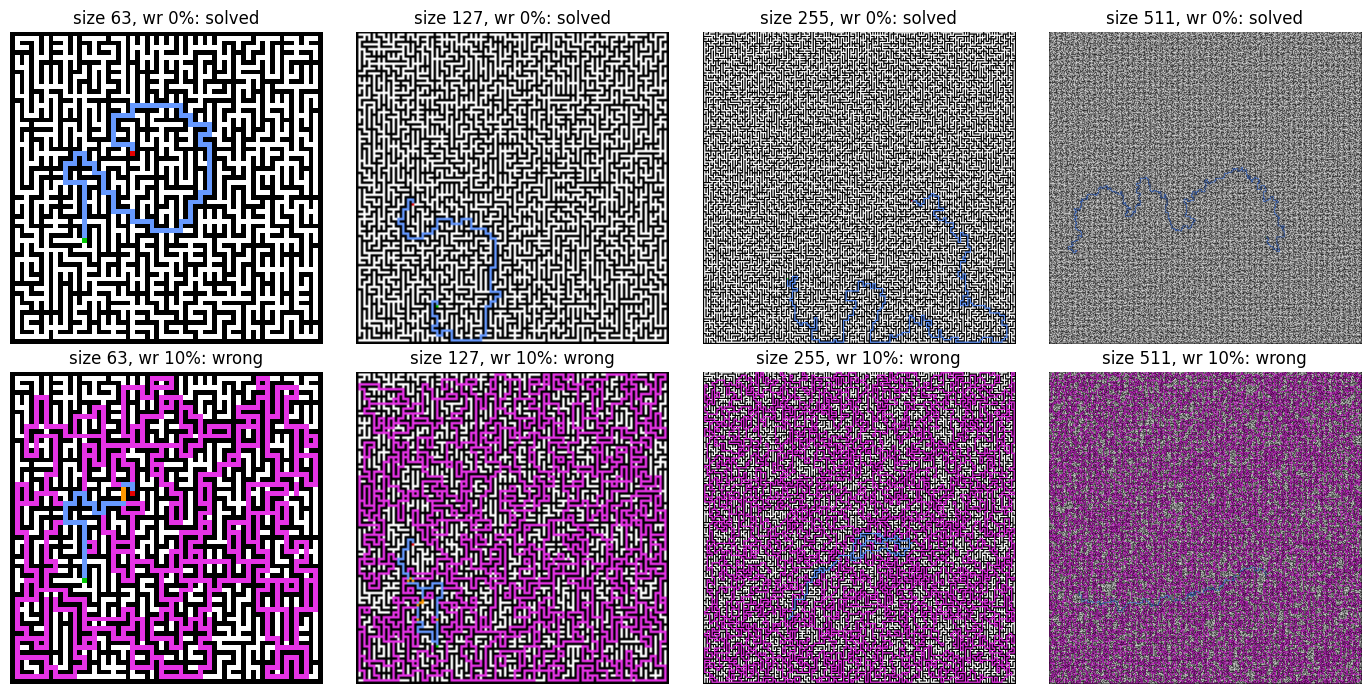

In [12]:
images, titles = [], []

for (wr, size), ds in tqdm(test_data.items(), desc="predictions"):
    x, y = ds[0]
    with autocast():
        pred = predict(model, x[None].float().to(device), max(TEST_ITERS))[0].cpu()
    ok = bool(((pred == y) | (x[:1] == 0)).all())
    images.append(render(x, y, pred))
    titles.append(f"size {size}, wr {wr:.0%}: {'solved' if ok else 'wrong'}")

show(images, titles, ncols=len(TEST_SIZES))